| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./3_2_Distribuciones.ipynb) |

# 1. El mapa general

Los conceptos que has elegido están conectados así:

```text
ESPACIO MUESTRAL
       │
       ▼
    EVENTOS
       │
       ▼
 PROBABILIDAD
       │
       ├──────────────┐
       ▼              ▼
CONDICIONAL      INDEPENDENCIA
       │
       ▼
      BAYES
       │
       ▼
VARIABLES ALEATORIAS
       │
       ▼
DISTRIBUCIONES
       │
       ├── Discretas
       └── Continuas
              │
              ▼
       Datos + incertidumbre
              │
              ▼
             ML
              │
              ▼
            SciML
```

La idea fundamental es:

$$
\boxed{\text{Probabilidad}=\text{matemática para modelar incertidumbre}}
$$

# 2. ESPACIO MUESTRAL

## 2.1 ¿Qué es?

El **espacio muestral** es el conjunto de todos los resultados posibles de un experimento aleatorio.

Se representa normalmente como:

$$
\boxed{\Omega}
$$

Por ejemplo, lanzar un dado:

$$
\Omega=\{1,2,3,4,5,6\}.
$$

Lanzar una moneda:

$$
\Omega=\{cara,\ cruz\}.
$$

Pero para SciML necesitamos ejemplos bastante más interesantes.

# 2.2 Ejemplo: medición científica

Supongamos que tienes un sensor de temperatura.

La temperatura real está alrededor de:

$$
25^\circ C
$$

pero el sensor tiene ruido.

Podríamos representar la medición como:

$$
\Omega=\mathbb R.
$$

Es decir, potencialmente cualquier número real puede ser observado:

$$
24.97,\quad25.02,\quad25.31,\quad24.81,\ldots
$$

Aquí aparece una diferencia fundamental:

### Probabilidad discreta


$$
\Omega=\{x_1,x_2,\ldots\}
$$

### Probabilidad continua

$$
\Omega\subseteq\mathbb R
$$

o incluso:

$$
\Omega\subseteq\mathbb R^n.
$$

Esto último es extremadamente importante en SciML.

# 2.3 Ejemplo difícil: posición de una partícula

Supongamos que una partícula puede estar en:

$$
(x,y,z)\in\mathbb R^3.
$$

Entonces:

$$
\boxed{\Omega=\mathbb R^3}
$$

Un evento podría ser:

> La partícula está dentro de una esfera de radio $(r)$.

Entonces:

$$
A=
\{(x,y,z):x^2+y^2+z^2\le r^2\}.
$$

Esto ya es probabilidad geométrica.

# 2.4 Aplicación en SciML

Supón que:

$$
\theta
$$

es un parámetro físico desconocido:

$$
\theta=\text{coeficiente de difusión}.
$$

No sabemos exactamente cuánto vale.

Entonces podemos modelarlo como una variable aleatoria:

$$
\theta:\Omega\rightarrow\mathbb R.
$$

Por ejemplo:

$$
\theta\sim N(\mu,\sigma^2).
$$

Así una simulación ya no tiene un único parámetro.

Tiene:

$$
\theta_1,\theta_2,\ldots,\theta_N.
$$

Esto lleva directamente a **uncertainty quantification**.

# 3. EVENTOS

Un **evento** es un subconjunto del espacio muestral:

$$
\boxed{A\subseteq\Omega}.
$$

Si lanzamos un dado:

$$
\Omega=\{1,2,3,4,5,6\}.
$$

Evento:

> obtener un número par.

Entonces:

$$
A=\{2,4,6\}.
$$

Por tanto:

$$
P(A)=\frac36=\frac12.
$$

# 3.1 Operaciones entre eventos

Esto es importante porque luego aparecerá en probabilidad condicional y Bayes.

## Unión

$$
A\cup B
$$

significa:

> ocurre $(A)$ o $(B)$.

## Intersección

$$
A\cap B
$$

significa:

> ocurren $(A)$ y $(B)$.

## Complemento

$$
A^c
$$

significa:

> no ocurre $(A)$.

# 3.2 Ejemplo difícil

Supongamos que una fábrica produce componentes.

Definimos:

$$
A=\{\text{componente defectuoso}\}
$$

y:

$$
B=\{\text{componente producido en turno nocturno}\}.
$$

Podemos preguntar:

$$
P(A)
$$

probabilidad de defecto.

Pero también:

$$
P(A\cap B)
$$

probabilidad de que sea defectuoso **y** producido de noche.

Y:

$$
P(A\cup B)
$$

probabilidad de que sea defectuoso **o** producido de noche.

# 3.3 Fórmula de inclusión-exclusión

$$
\boxed{
P(A\cup B)
=
P(A)+P(B)-P(A\cap B)
}
$$

El término:

$$
P(A\cap B)
$$

se resta porque lo contamos dos veces.

# 3.4 Python: visualizar eventos

Podemos visualizar dos eventos geométricos.

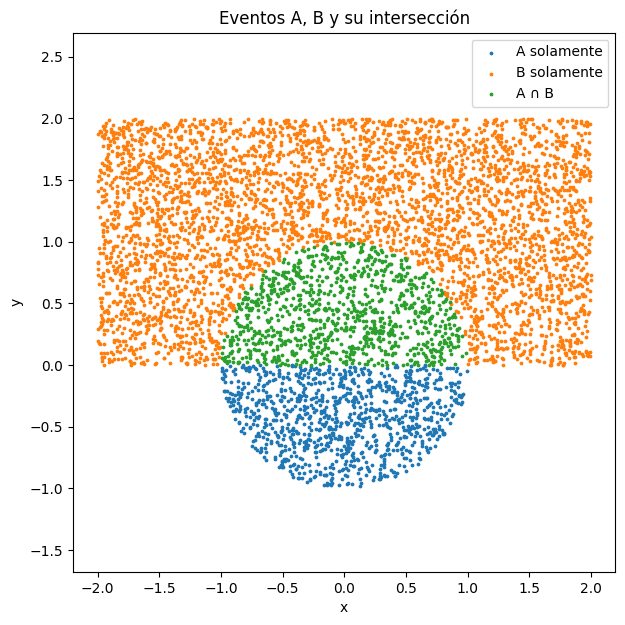

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

N = 10000

x = np.random.uniform(-2, 2, N)
y = np.random.uniform(-2, 2, N)

A = x**2 + y**2 <= 1
B = y >= 0

plt.figure(figsize=(7, 7))

plt.scatter(x[A & ~B], y[A & ~B], s=3,
            label="A solamente")

plt.scatter(x[~A & B], y[~A & B], s=3,
            label="B solamente")

plt.scatter(x[A & B], y[A & B], s=3,
            label="A ∩ B")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Eventos A, B y su intersección")
plt.legend()
plt.axis("equal")
plt.show()

Aquí:

$$
A=\{x^2+y^2\le1\}
$$

y:

$$
B=\{y\ge0\}.
$$

La intersección es:

$$
A\cap B.
$$

# 4. PROBABILIDAD CONDICIONAL

Ahora llegamos a uno de los conceptos más importantes de toda la probabilidad.

Queremos responder:

> ¿Cuál es la probabilidad de $(A)$ sabiendo que ocurrió $(B)$?

Se escribe:

$$
\boxed{P(A|B)}
$$

y se define como:

$$
\boxed{
P(A|B)=\frac{P(A\cap B)}{P(B)}
}
$$

si:

$$
P(B)>0.
$$

# 4.1 Ejemplo médico

Supongamos:

$$
P(D)=0.01
$$

donde $(D)$ significa:

> una persona tiene una enfermedad.

Un test tiene:

$$
P(+|D)=0.95
$$

y:

$$
P(+|D^c)=0.05.
$$

Pregunta:

> Si una persona da positivo, ¿cuál es la probabilidad de que realmente esté enferma?

Esto **no es simplemente 95%**.

Hay que utilizar Bayes.

Pero antes necesitamos entender bien la estructura.

# 4.2 Ejemplo con datos de una empresa

Supongamos:

|           | Defectuoso | No defectuoso |
| --------- | ---------: | ------------: |
| Máquina A |         20 |           980 |
| Máquina B |         50 |           950 |

La máquina A produce:

$$
1000
$$

unidades.

La B también:

$$
1000.
$$

Si escogemos una pieza defectuosa, podemos preguntar:

$$
P(A|\text{defectuoso}).
$$

Eso significa:

> ¿Cuál es la probabilidad de que la pieza haya sido fabricada por A sabiendo que es defectuosa?

Esta inversión del condicionamiento es precisamente donde Bayes aparece.

# 5. INDEPENDENCIA

Dos eventos $(A)$ y $(B)$ son independientes si conocer uno **no cambia** la probabilidad del otro.

Formalmente:

$$
\boxed{
P(A\cap B)=P(A)P(B)
}
$$

Equivalentemente:

$$
\boxed{
P(A|B)=P(A)
}
$$

si $(P(B)>0)$.

# 5.1 Ejemplo

Lanzas dos dados.

Define:

$$
A=\{\text{primer dado es 6}\}
$$

y:

$$
B=\{\text{segundo dado es 6}\}.
$$

Tenemos:

$$
P(A)=\frac16
$$

y:

$$
P(B)=\frac16.
$$

Como los dados son independientes:

$$
P(A\cap B)
=
\frac16\frac16
=
\frac1{36}.
$$

# 5.2 Ojo: independencia ≠ exclusión mutua

Esto es un error muy común.

Eventos mutuamente excluyentes:

$$
A\cap B=\varnothing.
$$

Entonces:

$$
P(A\cap B)=0.
$$

Pero si ambos tienen probabilidad positiva:

$$
P(A)>0,\qquad P(B)>0,
$$

no pueden ser independientes porque:

$$
P(A)P(B)>0.
$$

Por tanto:

$$
\boxed{\text{Mutuamente excluyentes} \neq \text{independientes}}
$$

# 5.3 Aplicación en Machine Learning

La independencia aparece constantemente.

Por ejemplo, un modelo puede asumir:

$$
P(x_1,x_2,\ldots,x_n)
=
\prod_iP(x_i).
$$

Esto reduce muchísimo la complejidad.

Un ejemplo clásico es **Naive Bayes**.

La hipótesis "naive" es precisamente una hipótesis de independencia condicional:

$$
P(x_1,\ldots,x_n|y)
=
\prod_iP(x_i|y).
$$

# 6. BAYES

Ahora llegamos a una de las fórmulas más importantes para ML y SciML.

Partimos de:

$$
P(A|B)
=
\frac{P(A\cap B)}{P(B)}
$$

y:

$$
P(B|A)
=
\frac{P(A\cap B)}{P(A)}.
$$

Entonces:

$$
P(A\cap B)=P(B|A)P(A).
$$

Sustituyendo:

$$
\boxed{
P(A|B)
=
\frac{P(B|A)P(A)}
{P(B)}
}
$$


# 6.1 Ejemplo difícil: detección de fraude

Supongamos:

$$
P(F)=0.002
$$

donde $(F)$ significa:

> una transacción es fraudulenta.

Tenemos un detector:

$$
P(+|F)=0.98
$$

pero también:

$$
P(+|F^c)=0.01.
$$

Queremos:

$$
P(F|+).
$$

Primero:

$$
P(+)
=
P(+|F)P(F)
+
P(+|F^c)P(F^c).
$$

Entonces:

$$
P(+)
=
0.98(0.002)+0.01(0.998).
$$

Por tanto:

$$
P(+)=0.01194.
$$

Ahora:

$$
P(F|+)
=
\frac{0.98(0.002)}
{0.01194}.
$$

Aproximadamente:

$$
\boxed{P(F|+)\approx0.164}
$$

o:

$$
\boxed{16.4\%}
$$

¡Aunque el detector tiene 98% de sensibilidad!

Esto demuestra la importancia de la **probabilidad base**.

# 6.2 Python

In [2]:
p_fraud = 0.002
p_positive_given_fraud = 0.98
p_positive_given_normal = 0.01

p_normal = 1 - p_fraud

p_positive = (
    p_positive_given_fraud * p_fraud
    + p_positive_given_normal * p_normal
)

p_fraud_given_positive = (
    p_positive_given_fraud * p_fraud
    / p_positive
)

print("P(+):", p_positive)
print("P(fraud | +):", p_fraud_given_positive)

P(+): 0.011940000000000001
P(fraud | +): 0.1641541038525963


# 6.3 Simulación Monte Carlo

También podemos comprobarlo mediante simulación.

In [3]:
import numpy as np

np.random.seed(123)

N = 2_000_000

fraud = np.random.random(N) < 0.002

positive = np.zeros(N, dtype=bool)

positive[fraud] = (
    np.random.random(np.sum(fraud)) < 0.98
)

normal_count = np.sum(~fraud)

positive[~fraud] = (
    np.random.random(normal_count) < 0.01
)

estimated_probability = np.mean(fraud[positive])

print(estimated_probability)

0.1586042823156225


Debería aproximarse a:

$$
0.164.
$$

Esta idea de **simular millones de realizaciones** es importantísima en SciML.

# 7. VARIABLES ALEATORIAS

Ahora damos un salto conceptual.

Una variable aleatoria no significa simplemente:

> "una variable que cambia aleatoriamente".

Formalmente es una función:

$$
\boxed{
X:\Omega\rightarrow\mathbb R
}
$$

que asigna un número real a cada resultado del experimento.

# 7.1 Ejemplo

Lanzas dos dados:

$$
\Omega=
\{(1,1),(1,2),\ldots,(6,6)\}.
$$

Definimos:

$$
X(i,j)=i+j.
$$

Entonces:

$$
X:\Omega\rightarrow\{2,3,\ldots,12\}.
$$

$(X)$ es una variable aleatoria.

# 7.2 Distribución de $(X)$

Las probabilidades son:

$$
P(X=2)=\frac1{36}
$$

$$
P(X=3)=\frac2{36}
$$

$$
P(X=4)=\frac3{36}
$$

...

$$
P(X=7)=\frac6{36}.
$$

Después vuelve a bajar.

# 7.3 Python

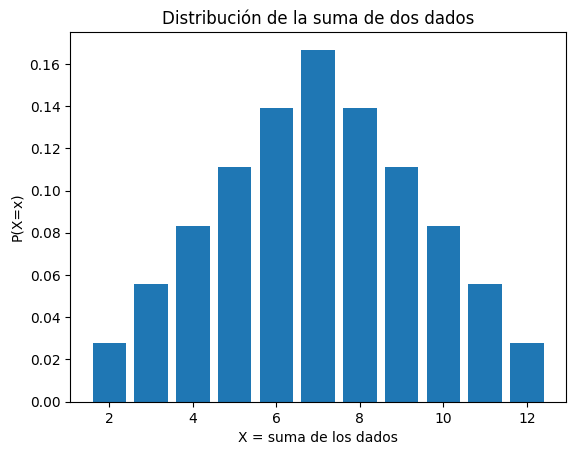

In [4]:
import numpy as np
import matplotlib.pyplot as plt

sums = []

for i in range(1, 7):
    for j in range(1, 7):
        sums.append(i + j)

values, counts = np.unique(sums, return_counts=True)

probabilities = counts / len(sums)

plt.figure()
plt.bar(values, probabilities)
plt.xlabel("X = suma de los dados")
plt.ylabel("P(X=x)")
plt.title("Distribución de la suma de dos dados")
plt.show()

# 8. VARIABLE ALEATORIA DISCRETA

Una variable aleatoria discreta toma valores contables:

$$
x_1,x_2,\ldots
$$

y tiene una función de masa:

$$
\boxed{
P(X=x)
}
$$

que cumple:

$$
P(X=x)\ge0
$$

y:

$$
\sum_xP(X=x)=1.
$$

# 8.1 Esperanza

La esperanza es:

$$
\boxed{
E[X]=\sum_xxP(X=x)
}
$$

Para una variable continua:

$$
\boxed{
E[X]=\int_{-\infty}^{\infty}xf_X(x)\,dx
}
$$

# 8.2 Varianza

La varianza:

$$
\boxed{
\operatorname{Var}(X)=E[(X-\mu)^2]
}
$$

donde:

$$
\mu=E[X].
$$

También:

$$
\boxed{
\operatorname{Var}(X)=E[X^2]-E[X]^2
}
$$

La desviación estándar:

$$
\boxed{
\sigma=\sqrt{\operatorname{Var}(X)}
}
$$

# 9. DISTRIBUCIONES

Aquí empieza una parte enorme de Probabilidad.

Las distribuciones son modelos matemáticos para variables aleatorias.

Hay dos grandes categorías.

```text
Distribuciones
│
├── Discretas
│   ├── Bernoulli
│   ├── Binomial
│   ├── Poisson
│   └── Geométrica
│
└── Continuas
    ├── Uniforme
    ├── Normal
    ├── Exponencial
    ├── Gamma
    ├── Beta
    └── Lognormal
```

Para SciML luego añadiremos:

* multivariate normal,
* Gaussian processes,
* distributions over functions,
* stochastic processes.

# 10. Bernoulli

Una variable Bernoulli tiene solamente:

$$
X\in\{0,1\}.
$$

Por ejemplo:

$$
X=
\begin{cases}
1&\text{éxito}\\
0&\text{fracaso}
\end{cases}
$$

con:

$$
P(X=1)=p
$$

y:

$$
P(X=0)=1-p.
$$

Su esperanza:

$$
E[X]=p.
$$

Su varianza:

$$
\boxed{
\operatorname{Var}(X)=p(1-p)
}
$$

# 11. Binomial

Si tenemos $(n)$ experimentos Bernoulli independientes:

$$
X\sim Binomial(n,p).
$$

Entonces:

$$
\boxed{
P(X=k)
=
{n\choose k}p^k(1-p)^{n-k}
}
$$

# 11.1 Ejemplo científico

Supongamos que un sensor tiene:

$$
p=0.02
$$

de producir una lectura defectuosa.

Medimos:

$$
n=1000
$$

veces.

¿Cuál es la probabilidad de exactamente 30 errores?

$$
P(X=30)
=
{1000\choose30}
(0.02)^{30}
(0.98)^{970}.
$$

En Python:

In [5]:
from scipy.stats import binom

n = 1000
p = 0.02

prob = binom.pmf(30, n, p)

print(prob)

0.008048770327126932


# 12. Poisson

Poisson modela conteos de eventos.

$$
\boxed{
P(X=k)=
\frac{e^{-\lambda}\lambda^k}{k!}
}
$$

donde:

$$
\lambda>0.
$$

Además:

$$
E[X]=\lambda
$$

y:

$$
\operatorname{Var}(X)=\lambda.
$$

# 12.1 Ejemplo real

Supongamos que un servidor recibe:

$$
\lambda=50
$$

solicitudes por segundo.

Entonces:

$$
X\sim Poisson(50).
$$

Podemos preguntar:

> ¿Cuál es la probabilidad de recibir exactamente 60 solicitudes?

In [6]:
from scipy.stats import poisson

lam = 50

prob = poisson.pmf(60, lam)

print(prob)

0.020104872145675377


# 12.2 Gráfico

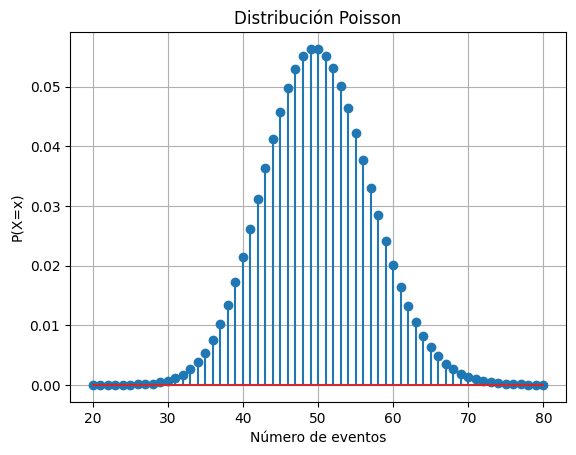

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 50

x = np.arange(20, 81)

pmf = poisson.pmf(x, lam)

plt.figure()
plt.stem(x, pmf)
plt.xlabel("Número de eventos")
plt.ylabel("P(X=x)")
plt.title("Distribución Poisson")
plt.grid()
plt.show()

# 13. Distribución uniforme

Si:

$$
X\sim U(a,b)
$$

entonces:

$$
f(x)=
\frac1{b-a}
$$

para:

$$
a\le x\le b.
$$

Por ejemplo:

$$
X\sim U(0,10).
$$

Esto significa que todos los valores del intervalo tienen la misma densidad.

# 14. Distribución normal

Ahora llegamos a posiblemente la distribución más importante de ML.

$$
\boxed{
X\sim N(\mu,\sigma^2)
}
$$

con:

$$
f(x)
=
\frac1{\sigma\sqrt{2\pi}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}.
$$

# 14.1 ¿Por qué es tan importante?

Porque aparece en:

* ruido de sensores,
* errores experimentales,
* estadística,
* regresión,
* Bayesian inference,
* Gaussian processes,
* Kalman filters,
* machine learning.

# 14.2 Ejemplo científico

Supón:

$$
T_{\text{real}}=25^\circ C.
$$

El sensor tiene ruido:

$$
\epsilon\sim N(0,0.5^2).
$$

Entonces:

$$
T_{\text{medido}}
=
25+\epsilon.
$$

Por tanto:

$$
T_{\text{medido}}
\sim
N(25,0.5^2).
$$

# 14.3 Python

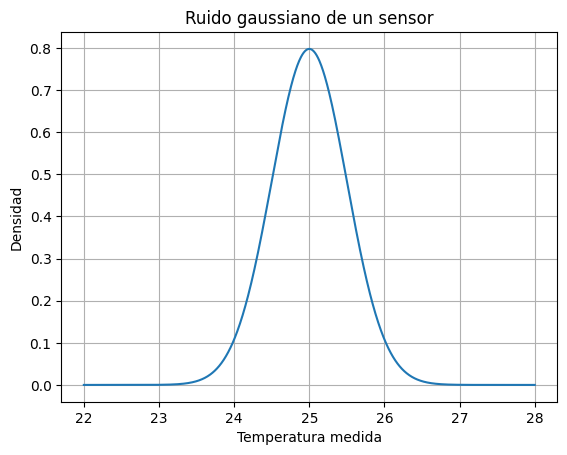

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 25
sigma = 0.5

x = np.linspace(22, 28, 1000)

pdf = norm.pdf(x, mu, sigma)

plt.figure()
plt.plot(x, pdf)
plt.xlabel("Temperatura medida")
plt.ylabel("Densidad")
plt.title("Ruido gaussiano de un sensor")
plt.grid()
plt.show()

# 15. Un ejemplo mucho más importante para SciML

Supongamos que tienes:

$$
y=f(x;\theta)+\epsilon
$$

donde:

$$
\epsilon\sim N(0,\sigma^2).
$$

Por ejemplo:

$$
y=\sin(\theta x)+\epsilon.
$$

Aquí:

* $(x)$ = entrada,
* $(\theta)$ = parámetro físico,
* $(y)$ = observación,
* $(\epsilon)$ = ruido.

Entonces:

$$
\boxed{
y|x,\theta
\sim
N(f(x;\theta),\sigma^2)
}
$$

Esto es muchísimo más profundo que simplemente "hay ruido".

Estamos construyendo un **modelo probabilístico del experimento**.

# 16. Python: datos científicos con ruido

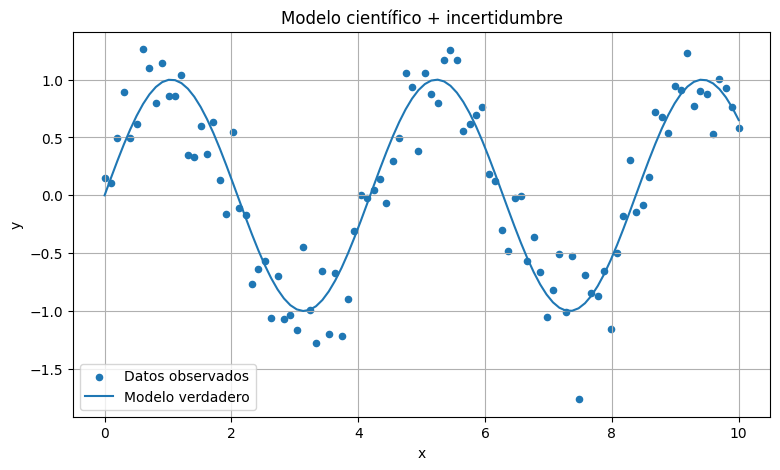

In [9]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

x = np.linspace(0, 10, 100)

theta = 1.5
sigma = 0.3

y_true = np.sin(theta * x)

noise = np.random.normal(0, sigma, size=len(x))

y_observed = y_true + noise

plt.figure(figsize=(9, 5))

plt.scatter(x, y_observed, s=20, label="Datos observados")
plt.plot(x, y_true, label="Modelo verdadero")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Modelo científico + incertidumbre")
plt.legend()
plt.grid()
plt.show()

Este pequeño ejemplo ya tiene una estructura fundamental de SciML:

$$
\boxed{
\text{Modelo físico}+\text{ruido}+\text{datos}
}
$$

# 17. La conexión con inferencia

Ahora imagina que **no conocemos**:

$$
\theta=1.5.
$$

Solo tenemos:

$$
(x_i,y_i).
$$

Queremos inferir:

$$
\theta.
$$

Entonces pasamos de:

$$
\theta\rightarrow y
$$

a:

$$
y\rightarrow\theta.
$$

Esto es un **inverse problem**.

Y aquí aparece Bayes:

$$
\boxed{
P(\theta|y)
=
\frac{P(y|\theta)P(\theta)}
{P(y)}
}
$$

donde:

### Prior

$$
P(\theta)
$$

representa lo que sabemos antes de observar los datos.

### Likelihood

$$
P(y|\theta)
$$

dice qué tan compatibles son los datos con $(\theta)$.

### Posterior

$$
P(\theta|y)
$$

es lo que creemos después de observar los datos.

Esto será fundamental cuando llegues a:

* Bayesian inference,
* Bayesian inverse problems,
* probabilistic machine learning,
* uncertainty quantification,
* Bayesian neural networks,
* scientific parameter estimation.

# 18. Distribuciones continuas: algo MUY importante

En una variable continua:

$$
P(X=x)=0
$$

para un punto individual.

Esto suele confundir al principio.

Si:

$$
X\sim N(0,1),
$$

entonces:

$$
P(X=0)=0.
$$

Pero:

$$
P(-1<X<1)>0.
$$

La probabilidad se calcula mediante:

$$
\boxed{
P(a<X<b)=
\int_a^b f_X(x)\,dx
}
$$

Por eso una **densidad de probabilidad no es una probabilidad**.

# 19. Una gráfica comparativa de distribuciones

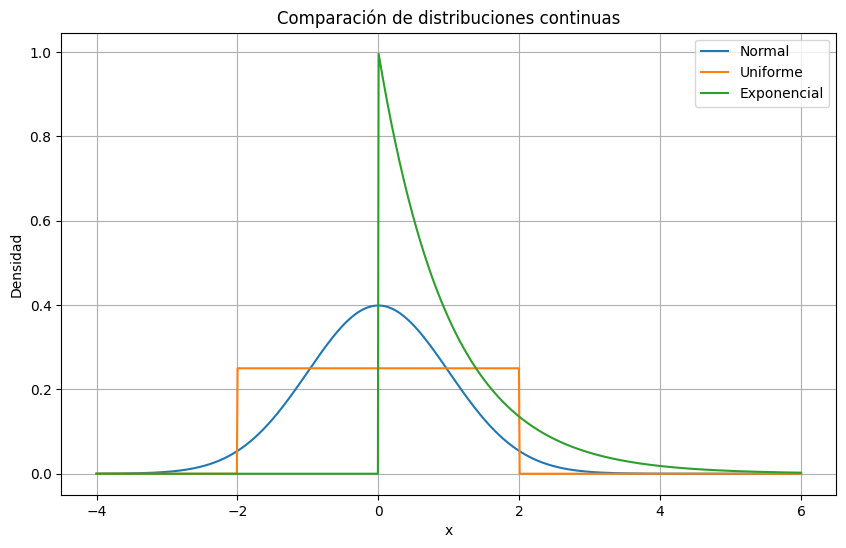

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, uniform, expon

x = np.linspace(-4, 6, 1000)

normal = norm.pdf(x, 0, 1)

uniform = uniform.pdf(x, -2, 4)

exponential = expon.pdf(x, scale=1)

plt.figure(figsize=(10, 6))

plt.plot(x, normal, label="Normal")
plt.plot(x, uniform, label="Uniforme")
plt.plot(x, exponential, label="Exponencial")

plt.xlabel("x")
plt.ylabel("Densidad")
plt.title("Comparación de distribuciones continuas")
plt.legend()
plt.grid()
plt.show()

Observa que cada distribución representa una hipótesis diferente sobre cómo se comporta la incertidumbre.

# 20. ¿Qué distribuciones debes dominar para SciML?

Yo las dividiría así:

## Nivel 1

Debes dominar:

$$
\boxed{
Bernoulli
}
$$

$$
\boxed{
Binomial
}
$$

$$
\boxed{
Poisson
}
$$

$$
\boxed{
Uniforme
}
$$

$$
\boxed{
Normal
}
$$

## Nivel 2

Después:

$$
\boxed{
Exponencial
}
$$

$$
\boxed{
Gamma
}
$$

$$
\boxed{
Beta
}
$$

$$
\boxed{
Lognormal
}
$$

$$
\boxed{
Weibull
}
$$

## Nivel 3 — fundamental para ML/SciML

Luego:

$$
\boxed{\text{Multivariate Normal}}
$$

porque:

$$
X\sim N(\mu,\Sigma)
$$

donde:

$$
\mu\in\mathbb R^n
$$

y:

$$
\Sigma\in\mathbb R^{n\times n}.
$$

Aquí se conecta directamente con lo que ya estudiaste de:

* matrices,
* eigenvalues,
* SVD,
* positive definite matrices,
* Cholesky.

# 21. Una conexión espectacular: Cholesky + Gaussian

Supón:

$$
X\sim N(\mu,\Sigma).
$$

Si:

$$
\Sigma=LL^T,
$$

podemos generar muestras mediante:

$$
\boxed{
X=\mu+LZ
}
$$

donde:

$$
Z\sim N(0,I).
$$

Esto conecta directamente:

$$
\boxed{
Probabilidad
\rightarrow
Matrices
\rightarrow
Cholesky
\rightarrow
Monte Carlo
\rightarrow
SciML
}
$$

Python:

In [11]:
import numpy as np

np.random.seed(42)

mu = np.array([2., 1.])

Sigma = np.array([
    [2.0, 1.2],
    [1.2, 1.5]
])

L = np.linalg.cholesky(Sigma)

N = 10000

Z = np.random.randn(N, 2)

X = mu + Z @ L.T

Ahora `X` contiene muestras de una distribución normal multivariada.

Podemos visualizarla:

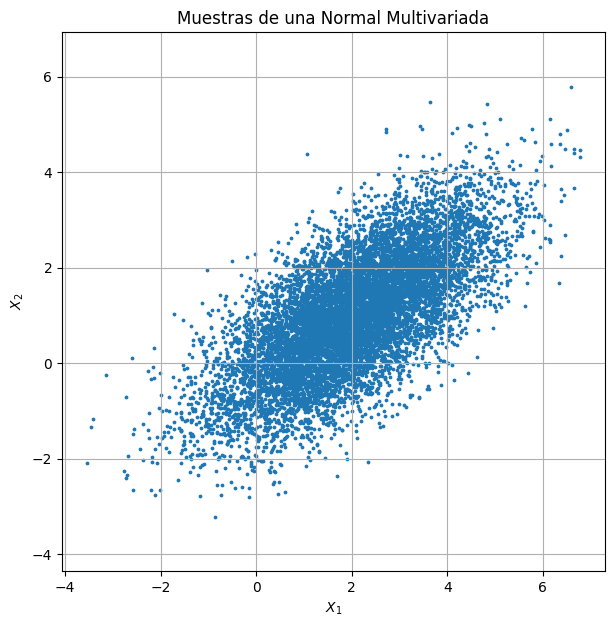

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(X[:, 0], X[:, 1], s=3)

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Muestras de una Normal Multivariada")
plt.axis("equal")
plt.grid()
plt.show()

Aquí puedes observar cómo la matriz de covarianza determina la orientación y dispersión de la nube.

# 22. Esto conecta directamente con lo que acabas de estudiar

Mira la cadena:

$$
\boxed{
\Sigma
}
$$

es una matriz de covarianza.

Para que sea válida:

$$
\Sigma\succeq0.
$$

La descomponemos:

$$
\Sigma=LL^T
$$

mediante **Cholesky**.

También podemos utilizar eigenvalues:

$$
\Sigma=Q\Lambda Q^T.
$$

Y SVD.

Entonces:

$$
\boxed{
\text{Probabilidad}
\leftrightarrow
\text{Álgebra lineal}
}
$$

no son dos materias aisladas.

# 23. La conexión final con SciML

Ahora piensa en una PDE:

$$
u_t=\mathcal F(u,\theta).
$$

Pero los parámetros:

$$
\theta
$$

no son perfectamente conocidos.

Entonces:

$$
\theta\sim p(\theta).
$$

La solución se convierte en una variable aleatoria:

$$
u(x,t;\theta).
$$

Por tanto, ya no buscas solamente:

$$
u(x,t).
$$

Ahora quieres conocer:

$$
E[u(x,t)]
$$

y:

$$
\operatorname{Var}[u(x,t)].
$$

Incluso puedes querer:

$$
P(u(x,t)>u_{\text{critical}}).
$$

Esto es:

$$
\boxed{\text{Uncertainty Quantification}}
$$

y es una parte importante del ecosistema SciML.

# 24. Ejemplo conceptual completo

Supongamos una ecuación de difusión:

$$
u_t=\alpha u_{xx}
$$

pero:

$$
\alpha\sim N(\mu_\alpha,\sigma_\alpha^2).
$$

Entonces ejecutamos la simulación muchas veces:

$$
\alpha_1,\alpha_2,\ldots,\alpha_N.
$$

Obtenemos:

$$
u_1(x,t),u_2(x,t),\ldots,u_N(x,t).
$$

Calculamos:

$$
\hat E[u(x,t)]
=
\frac1N
\sum_{i=1}^Nu_i(x,t).
$$

Y:

$$
\widehat{\operatorname{Var}}(u)
=
\frac1{N-1}
\sum_i
(u_i-\bar u)^2.
$$

Ahora podemos visualizar:

$$
\boxed{
\text{solución media}\pm\text{incertidumbre}
}
$$

Esto es una de las ideas fundamentales detrás de **uncertainty quantification + scientific computing**.

| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./3_2_Distribuciones.ipynb) |